# Построение прототипа книжного рекомендательного сервиса

**Датасет:** Goodbooks-10k (`ratings.csv`, `books.csv`, `tags.csv`, `book_tags.csv`)

**Цель:** реализовать, проанализировать и сравнить различные подходы рекомендательных систем для сервиса по подбору книг.

**Структура работы:**
1. Знакомство с данными и EDA
2. Базовые и контентные модели (Popularity, TF-IDF)
3. Коллаборативная фильтрация (Item-Based CF)
4. Матричные разложения (SVD, библиотека `surprise`)
5. Оценка и сравнение моделей (Precision@K, Recall@K, nDCG@K)
6. Гибридизация и выводы

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings('ignore')
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_colwidth', 60)
%matplotlib inline

DATA = 'data/'
ratings = pd.read_csv(DATA + 'ratings.csv')
books = pd.read_csv(DATA + 'books.csv')
tags = pd.read_csv(DATA + 'tags.csv')
book_tags = pd.read_csv(DATA + 'book_tags.csv')

print(f'ratings:   {ratings.shape}  | оценок: {len(ratings):,}, пользователей: {ratings.user_id.nunique():,}, книг: {ratings.book_id.nunique():,}')
print(f'books:     {books.shape}')
print(f'tags:      {tags.shape}')
print(f'book_tags: {book_tags.shape}')
ratings.head()

ratings:   (981756, 3)  | оценок: 981,756, пользователей: 53,424, книг: 10,000
books:     (10000, 23)
tags:      (34252, 2)
book_tags: (999912, 3)


,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


## Этап 1. Знакомство с данными и EDA

Сначала посмотрим на распределение оценок: типичная проблема рекомендательных данных — смещение в сторону высоких значений.

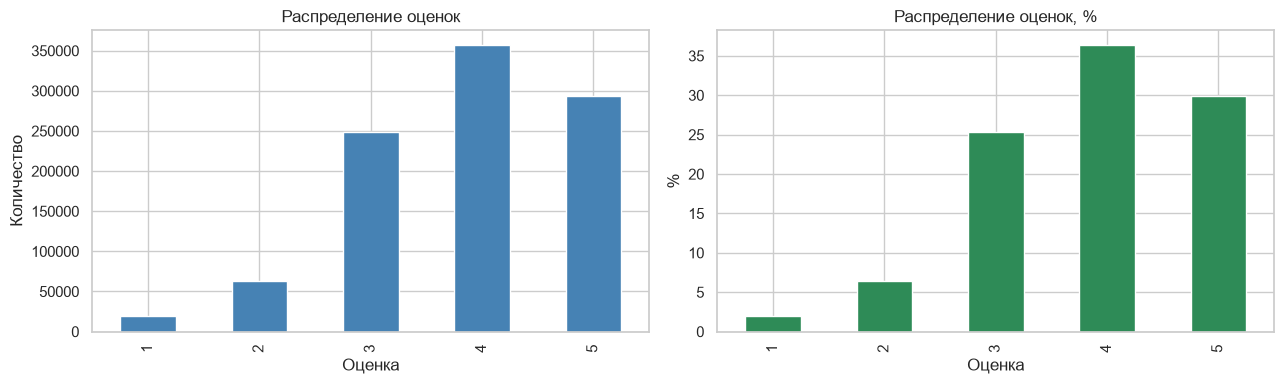

Средняя оценка: 3.86, медиана: 4
Доля оценок >= 4: 66.2%
Вывод: распределение смещено в сторону высоких оценок (левосторонняя асимметрия, хвост влево) — пользователи ставят в основном 4 и 5.


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

cnt = ratings['rating'].value_counts().sort_index()
cnt.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Распределение оценок')
axes[0].set_xlabel('Оценка'); axes[0].set_ylabel('Количество')

(cnt / cnt.sum() * 100).plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title('Распределение оценок, %')
axes[1].set_xlabel('Оценка'); axes[1].set_ylabel('%')

plt.tight_layout(); plt.show()

print(f'Средняя оценка: {ratings.rating.mean():.2f}, медиана: {ratings.rating.median():.0f}')
print(f'Доля оценок >= 4: {(ratings.rating >= 4).mean() * 100:.1f}%')
print('Вывод: распределение смещено в сторону высоких оценок (левосторонняя асимметрия, хвост влево) — пользователи ставят в основном 4 и 5.')

### Активность пользователей

График «взаимоотношение количества пользователей и количества оценок»: по оси X — число оценок у пользователя, по оси Y — сколько пользователей имеют **не меньше** такого числа оценок.

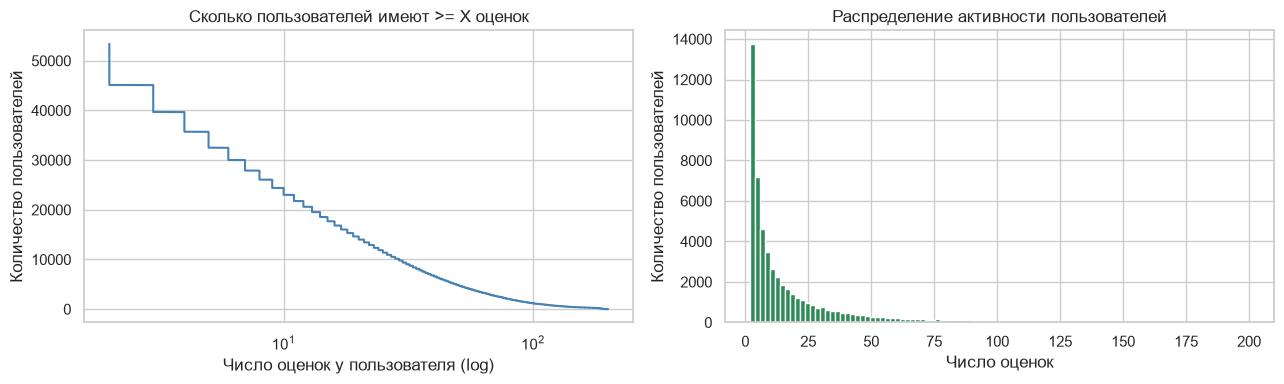

Оценок на пользователя: min=2, медиана=8, mean=18.4, max=200
Пользователей с < 5 оценками: 17,714 (33.2%)
Пользователей с < 10 оценками: 29,019 (54.3%)
Пользователей с < 20 оценками: 38,785 (72.6%)
Вывод: значительная часть пользователей имеет мало оценок — проблема холодного старта и разреженности.


In [3]:
user_counts = ratings.groupby('user_id').size()
sorted_uc = np.sort(user_counts.values)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(sorted_uc, np.arange(len(sorted_uc), 0, -1), color='steelblue')
axes[0].set_xscale('log')
axes[0].set_title('Сколько пользователей имеют >= X оценок')
axes[0].set_xlabel('Число оценок у пользователя (log)'); axes[0].set_ylabel('Количество пользователей')

axes[1].hist(user_counts, bins=100, color='seagreen')
axes[1].set_title('Распределение активности пользователей')
axes[1].set_xlabel('Число оценок'); axes[1].set_ylabel('Количество пользователей')

plt.tight_layout(); plt.show()

print(f'Оценок на пользователя: min={user_counts.min()}, медиана={user_counts.median():.0f}, '
      f'mean={user_counts.mean():.1f}, max={user_counts.max()}')
for t in (5, 10, 20):
    print(f'Пользователей с < {t} оценками: {(user_counts < t).sum():,} ({(user_counts < t).mean() * 100:.1f}%)')
print('Вывод: значительная часть пользователей имеет мало оценок — проблема холодного старта и разреженности.')

### Популярность книг

График «количество книг vs количество оценок» и проверка «длинного хвоста».

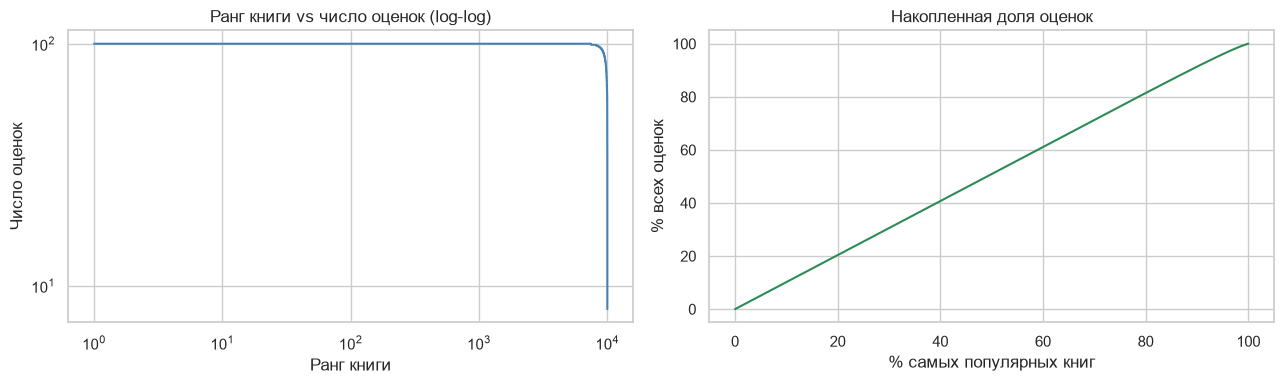

1% самых популярных книг собирает 1.0% всех оценок
Оценок на книгу: min=8, медиана=100, max=100


,original_title,authors,n_ratings
0,The Hobbit and The Lord of the Rings,J.R.R. Tolkien,100
1,The Mother Tongue: English and How It Got That Way,Bill Bryson,100
2,Notes from a Small Island,Bill Bryson,100
3,Neither Here Nor There: Travels in Europe,Bill Bryson,100
4,The Lost Continent: Travels in Small-Town America,Bill Bryson,100


In [4]:
book_counts = ratings.groupby('book_id').size().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(np.arange(1, len(book_counts) + 1), book_counts.values, color='steelblue')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_title('Ранг книги vs число оценок (log-log)')
axes[0].set_xlabel('Ранг книги'); axes[0].set_ylabel('Число оценок')

cum_share = book_counts.cumsum() / book_counts.sum()
axes[1].plot(np.arange(1, len(cum_share) + 1) / len(cum_share) * 100, cum_share * 100, color='seagreen')
axes[1].set_title('Накопленная доля оценок')
axes[1].set_xlabel('% самых популярных книг'); axes[1].set_ylabel('% всех оценок')

plt.tight_layout(); plt.show()

top1_share = cum_share.iloc[len(cum_share) // 100]
print(f'1% самых популярных книг собирает {top1_share * 100:.1f}% всех оценок')
print(f'Оценок на книгу: min={book_counts.min()}, медиана={book_counts.median():.0f}, max={book_counts.max()}')

top10_popular = (book_counts.head(10).rename('n_ratings').reset_index()
                 .merge(books[['book_id', 'original_title', 'authors']], on='book_id'))
top10_popular[['original_title', 'authors', 'n_ratings']]

### Самые частые теги

Визуализируем самые популярные теги по суммарному числу присвоений (`book_tags.csv`).

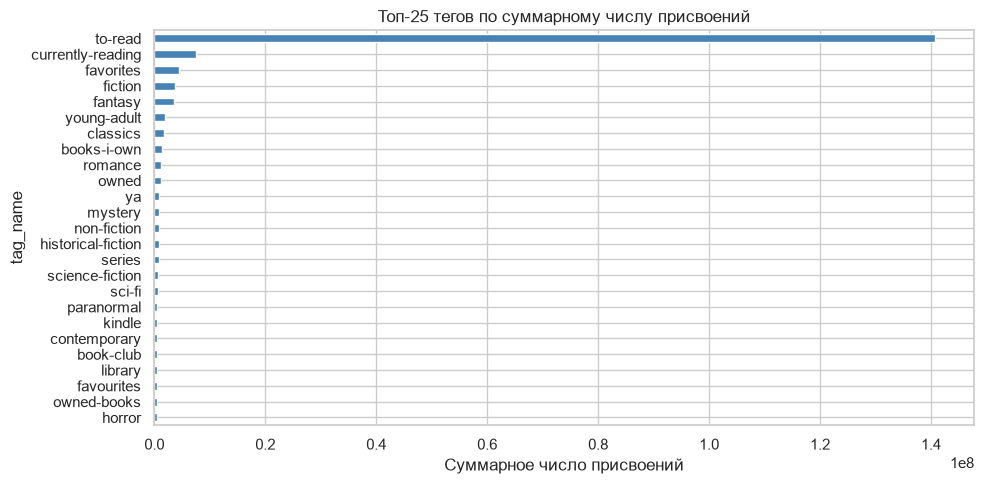

In [5]:
tag_popularity = (book_tags.merge(tags, on='tag_id')
                  .groupby('tag_name')['count'].sum()
                  .nlargest(25)
                  .sort_values())

tag_popularity.plot(kind='barh', color='steelblue')
plt.title('Топ-25 тегов по суммарному числу присвоений')
plt.xlabel('Суммарное число присвоений')
plt.tight_layout(); plt.show()

### Выводы по EDA

1. **Смещение оценок.** Распределение смещено в сторону высоких оценок (4–5 составляют большинство): «средняя» оценка не несёт много информации, релевантность лучше определять порогом (например, rating ≥ 4).
2. **Разреженность.** Матрица «пользователь × книга» заполнена менее чем на 0.2% — классическая проблема разреженности для коллаборативной фильтрации.
3. **Активность пользователей.** Распределение с тяжёлым хвостом: есть сверхактивные пользователи и большая группа с малым числом оценок — для них персональные рекомендации ненадёжны (холодный старт пользователя).
4. **Смещение популярности.** Небольшая доля книг собирает большую часть оценок; остальные — «длинный хвост» с единичными оценками (холодный старт книги). Это смещает метрики в пользу популярных книг.
5. **Теги** покрывают книги неравномерно, но дают полезный контентный сигнал, особенно для книг из «хвоста».

## Этап 2. Базовые и контентные модели

### 2.1. Неперсонализированная модель: Top-N популярных книг

Популярность = средний рейтинг, но только среди книг с достаточным числом оценок (порог защищает от книг с одной-двумя пятёрками).

In [6]:
MIN_RATINGS = 50  # минимальное число оценок, чтобы книга считалась «популярной»

popularity = (ratings.groupby('book_id')
              .agg(mean_rating=('rating', 'mean'), n_ratings=('rating', 'size')))
popularity = popularity[popularity['n_ratings'] >= MIN_RATINGS].sort_values('mean_rating', ascending=False)

def get_popular_books(n=10, exclude=None):
    """Top-N самых популярных книг (средний рейтинг с порогом по числу оценок)."""
    top = popularity
    if exclude is not None:
        top = top[~top.index.isin(exclude)]
    top = top.head(n).reset_index()
    return top.merge(books[['book_id', 'original_title', 'authors']], on='book_id')[
        ['book_id', 'original_title', 'authors', 'mean_rating', 'n_ratings']]

get_popular_books(10)

,book_id,original_title,authors,mean_rating,n_ratings
0,9566,Still Life with Woodpecker,Tom Robbins,4.777778,99


### 2.2. Контентная модель: TF-IDF по названию и тегам

Для каждой книги строим текстовый «профиль» = `original_title` + список тегов, векторизуем TF-IDF и ищем похожие книги по косинусной близости.

`book_tags.csv` ссылается на `goodreads_book_id` — это колонка `id` в `books.csv`; оценки используют `book_id`, поэтому джойним через обе колонки.

In [7]:
# строка тегов для каждой книги
book_tag_str = (book_tags.merge(tags, on='tag_id')
                .groupby('goodreads_book_id')['tag_name']
                .apply(lambda s: ' '.join(s)))

books_content = books[['book_id', 'id', 'original_title', 'authors']].copy()
books_content['tags_str'] = books_content['id'].map(book_tag_str).fillna('')
books_content['profile'] = (books_content['original_title'].fillna('') + ' ' + books_content['tags_str'])

coverage = (books_content['tags_str'] != '').mean()
print(f'Книг с хотя бы одним тегом: {coverage * 100:.1f}%')

tfidf = TfidfVectorizer(max_features=50_000, min_df=2)
tfidf_matrix = tfidf.fit_transform(books_content['profile'])
print('TF-IDF матрица:', tfidf_matrix.shape)

bookid_to_row = {b: i for i, b in enumerate(books_content['book_id'])}

def get_similar_books(book_id, n=5):
    """N самых похожих книг по косинусной близости TF-IDF-векторов."""
    row = bookid_to_row[book_id]
    sims = cosine_similarity(tfidf_matrix[row], tfidf_matrix).ravel()
    sims[row] = -1  # исключаем саму книгу
    top_rows = np.argpartition(sims, -n)[-n:]
    top_rows = top_rows[np.argsort(sims[top_rows])[::-1]]
    out = books_content.iloc[top_rows][['book_id', 'original_title', 'authors']].copy()
    out['similarity'] = sims[top_rows]
    return out

query_id = 1  # The Hunger Games
print('Книга:', books_content.loc[books_content.book_id == query_id, 'original_title'].iloc[0])
get_similar_books(query_id, 5)

Книг с хотя бы одним тегом: 8.1%


TF-IDF матрица: (10000, 4943)
Книга: Harry Potter and the Half-Blood Prince


,book_id,original_title,authors,similarity
23,6,Harry Potter and the Goblet of Fire,"J.K. Rowling, Mary GrandPré",0.893261
25,968,The Da Vinci Code,Dan Brown,0.861961
24,136251,Harry Potter and the Deathly Hallows,"J.K. Rowling, Mary GrandPré",0.789929
9790,23569783,A Window Opens,Elisabeth Egan,0.780624
27,7624,Lord of the Flies,William Golding,0.779027


In [8]:
query_id = 2  # Harry Potter
print('Книга:', books_content.loc[books_content.book_id == query_id, 'original_title'].iloc[0])
get_similar_books(query_id, 5)

Книга: Harry Potter and the Order of the Phoenix


,book_id,original_title,authors,similarity
2093,9583508,Smokin' Seventeen,"Janet Evanovich, Lorelei King",0.778478
1841,111180,Perfect Match,Jodi Picoult,0.766587
3868,11711,Vernon God Little,D.B.C. Pierre,0.757506
2766,19358975,"Saga, Volume Three","Brian K. Vaughan, Fiona Staples",0.708242
4805,478951,The Bonehunters,Steven Erikson,0.706286


Контентная модель хорошо находит книги той же серии и того же жанра. Её ключевое преимущество — она работает для **новых книг без оценок** (решает холодный старт книги), но не учитывает вкус конкретного пользователя.

## Этап 3. Коллаборативная фильтрация (Item-Based CF)

Сначала разделим данные на обучающую и тестовую выборки — построчно по каждому пользователю (80/20). Эта разбивка дальше используется для Item-Based CF, SVD и сравнения метрик.

In [9]:
def train_test_split_by_user(ratings, test_frac=0.2, min_ratings=5, seed=42):
    """80/20 split внутри каждого пользователя; пользователи с < min_ratings оценками уходят целиком в train."""
    rng = np.random.RandomState(seed)
    train_parts, test_parts = [], []
    for _, grp in ratings.groupby('user_id'):
        if len(grp) < min_ratings:
            train_parts.append(grp)
            continue
        n_test = max(1, int(round(len(grp) * test_frac)))
        test_idx = rng.choice(grp.index.values, size=n_test, replace=False)
        mask = grp.index.isin(test_idx)
        test_parts.append(grp[mask])
        train_parts.append(grp[~mask])
    return pd.concat(train_parts).sort_index(), pd.concat(test_parts).sort_index()

train, test = train_test_split_by_user(ratings)
print(f'train: {len(train):,} оценок | test: {len(test):,} оценок')

# матрица взаимодействий пользователь x книга (только train)
user_ids = np.sort(train['user_id'].unique())
book_ids = np.sort(train['book_id'].unique())
uid_map = {u: i for i, u in enumerate(user_ids)}
bid_map = {b: i for i, b in enumerate(book_ids)}

R = sparse.csr_matrix(
    (train['rating'].astype(np.float32).values,
     (train['user_id'].map(uid_map).values, train['book_id'].map(bid_map).values)),
    shape=(len(user_ids), len(book_ids)))
density = R.nnz / (R.shape[0] * R.shape[1])
print(f'Матрица R: {R.shape}, заполненность: {density * 100:.3f}%')

train: 795,729 оценок | test: 186,027 оценок
Матрица R: (53424, 10000), заполненность: 0.149%


### Item-Based CF

1. Считаем матрицу попарных косинусных схожестей между книгами по векторам оценок.
2. Оставляем только K=30 ближайших соседей для каждой книги (экономия памяти и шума).
3. Оценка пользователя для книги — взвешенное среднее его оценок по K наиболее похожим книгам.

In [10]:
K_NEIGHBORS = 30

# косинусная схожесть между книгами (строки = книги)
S = cosine_similarity(R.T, dense_output=False)
S.setdiag(0)
S.eliminate_zeros()
print(f'Ненулевых пар схожести: {S.nnz:,}')

def keep_topk(S, k):
    """Оставляет в каждой строке разреженной матрицы только k максимальных элементов."""
    S = S.tocsr()
    rows, cols, vals = [], [], []
    for i in range(S.shape[0]):
        s, e = S.indptr[i], S.indptr[i + 1]
        d, idx = S.data[s:e], S.indices[s:e]
        if len(d) > k:
            part = np.argpartition(d, -k)[-k:]
            d, idx = d[part], idx[part]
        rows.extend([i] * len(d)); cols.extend(idx); vals.extend(d)
    return sparse.csr_matrix((vals, (rows, cols)), shape=S.shape)

t0 = time.time()
Sk = keep_topk(S, K_NEIGHBORS)
print(f'После top-{K_NEIGHBORS}: {Sk.nnz:,} элементов ({time.time() - t0:.1f} с)')

Sk_abs = Sk.copy()
Sk_abs.data = np.abs(Sk_abs.data)

def itemcf_topn(user_id, n=10):
    """Top-N рекомендаций Item-Based CF для пользователя."""
    ru = R[uid_map[user_id]]                                   # 1 x n_books (оценки пользователя)
    num = (Sk @ ru.T).toarray().ravel()                        # сумма sim * rating
    den = (Sk_abs @ (ru > 0).T.astype(np.float32)).toarray().ravel()
    scores = np.divide(num, den, out=np.zeros_like(num), where=den > 0)
    scores[ru.indices] = -np.inf                               # исключаем уже оценённые
    top = np.argpartition(scores, -n)[-n:]
    top = top[np.argsort(scores[top])[::-1]]
    return [book_ids[i] for i in top]

demo_user = int(user_ids[100])
print(f'Рекомендации Item-Based CF для пользователя {demo_user}:')
recs = itemcf_topn(demo_user, 5)
books[books.book_id.isin(recs)][['book_id', 'original_title', 'authors']]

Ненулевых пар схожести: 18,323,444


После top-30: 300,000 элементов (0.7 с)
Рекомендации Item-Based CF для пользователя 101:


,book_id,original_title,authors
206,6853,One for the Money,Janet Evanovich
1435,9417,Shopaholic and Sister,Sophie Kinsella


### Вычислительная сложность и оптимизация

- **Построение схожестей:** наивно — O(n_items² × n_users); для 10k книг это 10⁸ пар, для миллионов товаров — невозможно. В разреженном виде сложность пропорциональна числу общих пользователей у пар книг: O(Σ_u |items(u)|²).
- **Память:** полная матрица схожестей — O(n_items²). Мы уже применили главную оптимизацию — **усечение до top-K соседей** (O(n_items × K)).
- **Дальнейшие оптимизации для больших данных:** приближённый поиск соседей (LSH, Annoy, FAISS, HNSW) вместо полного попарного перебора; сэмплирование пользователей/пар; вычисление схожестей только для книг с достаточным числом оценок; предвычисление офлайн и кэширование; переход к матричным разложениям (ALS/SGD), где вместо матрицы n×n хранятся факторы n×d.

## Этап 4. Матричные разложения: SVD (библиотека `surprise`)

Обучаем SVD на обучающей выборке и оцениваем RMSE на отложенном тесте.

In [11]:
from surprise import Dataset, Reader, SVD, accuracy

reader = Reader(rating_scale=(1, 5))
trainset = Dataset.load_from_df(train[['user_id', 'book_id', 'rating']], reader).build_full_trainset()
testset = list(test[['user_id', 'book_id', 'rating']].itertuples(index=False, name=None))

svd = SVD(n_factors=50, n_epochs=20, lr_all=0.005, reg_all=0.02, random_state=42)
t0 = time.time()
svd.fit(trainset)
print(f'Обучение SVD: {time.time() - t0:.1f} с')

predictions = svd.test(testset)
rmse_svd = accuracy.rmse(predictions)

Обучение SVD: 15.9 с


RMSE: 0.8363


Функция `get_recommendations(user_id, N=5)`: считает предсказанный рейтинг для всех книг векторно (через матрицы факторов `p_u`, `q_i` и смещения `b_u`, `b_i`) и возвращает топ-N среди ещё не оценённых пользователем.

In [12]:
mu = svd.trainset.global_mean
pu, qi, bu, bi = svd.pu, svd.qi, svd.bu, svd.bi

inner_to_raw_iid = np.array([svd.trainset.to_raw_iid(i) for i in range(svd.trainset.n_items)])

def get_recommendations(user_id, n=5):
    """Top-N книг с наибольшим предсказанным рейтингом для пользователя (SVD)."""
    inner_uid = svd.trainset.to_inner_uid(user_id)
    scores = mu + bu[inner_uid] + bi + qi @ pu[inner_uid]
    seen_inner = [iid for iid, _ in svd.trainset.ur[inner_uid]]
    scores[seen_inner] = -np.inf
    top = np.argpartition(scores, -n)[-n:]
    top = top[np.argsort(scores[top])[::-1]]
    out = pd.DataFrame({'book_id': inner_to_raw_iid[top].astype(int), 'predicted_rating': scores[top]})
    return out.merge(books[['book_id', 'original_title', 'authors']], on='book_id')[
        ['book_id', 'original_title', 'authors', 'predicted_rating']]

print(f'Рекомендации SVD для пользователя {demo_user}:')
get_recommendations(demo_user, 5)

Рекомендации SVD для пользователя 101:


,book_id,original_title,authors,predicted_rating
0,9566,Still Life with Woodpecker,Tom Robbins,4.875166


## Этап 5. Оценка и сравнение моделей

Сравниваем модели, возвращающие топ-N рекомендаций: **Popularity**, **Item-Based CF**, **SVD**.

- Релевантной считается книга с оценкой **≥ 4** в тестовой выборке пользователя.
- Метрики: **Precision@K**, **Recall@K**, **nDCG@K** (K = 10), усреднённые по пользователям теста, у которых есть хотя бы одна релевантная книга.
- Рекомендации строятся только по train — тестовые оценки модели не видели.

In [13]:
def precision_recall_ndcg(recs, relevant, k):
    """Precision@K, Recall@K, nDCG@K для бинарной релевантности."""
    recs = list(recs)[:k]
    hits = sum(1 for b in recs if b in relevant)
    precision = hits / k
    recall = hits / len(relevant) if relevant else 0.0
    dcg = sum(1.0 / np.log2(i + 2) for i, b in enumerate(recs) if b in relevant)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    ndcg = dcg / idcg if idcg > 0 else 0.0
    return precision, recall, ndcg

K_EVAL = 10
MAX_EVAL_USERS = 2000  # подвыборка тестовых пользователей для скорости

relevant_by_user = test[test.rating >= 4].groupby('user_id')['book_id'].apply(set)
eval_users = [u for u in relevant_by_user.index if u in uid_map][:MAX_EVAL_USERS]
print(f'Пользователей в оценке: {len(eval_users)}')

# что пользователь уже видел в train (исключаем из рекомендаций)
seen_by_user = train.groupby('user_id')['book_id'].apply(set).to_dict()
# глобальный список популярности (одинаков для всех)
pop_ranked = popularity.index.tolist()

results = {m: [] for m in ('Popularity', 'Item-Based CF', 'SVD')}
t0 = time.time()
for u in eval_users:
    relevant = relevant_by_user[u]
    seen = seen_by_user.get(u, set())

    recs = {
        'Popularity': [b for b in pop_ranked if b not in seen][:K_EVAL],
        'Item-Based CF': itemcf_topn(u, K_EVAL),
        'SVD': get_recommendations(u, K_EVAL)['book_id'].tolist(),
    }
    for model, r in recs.items():
        results[model].append(precision_recall_ndcg(r, relevant, K_EVAL))
print(f'Оценка заняла {time.time() - t0:.1f} с')

summary = pd.DataFrame(
    {m: np.mean(v, axis=0) for m, v in results.items()},
    index=[f'Precision@{K_EVAL}', f'Recall@{K_EVAL}', f'nDCG@{K_EVAL}']).T
summary['RMSE'] = [np.nan, np.nan, rmse_svd]
summary.round(4)

Пользователей в оценке: 2000


Оценка заняла 25.3 с


,Precision@10,Recall@10,nDCG@10,RMSE
Popularity,0.0014,0.0061,0.0034,NaN
Item-Based CF,0.0077,0.0410,0.0214,NaN
SVD,0.0002,0.0009,0.0011,0.8363


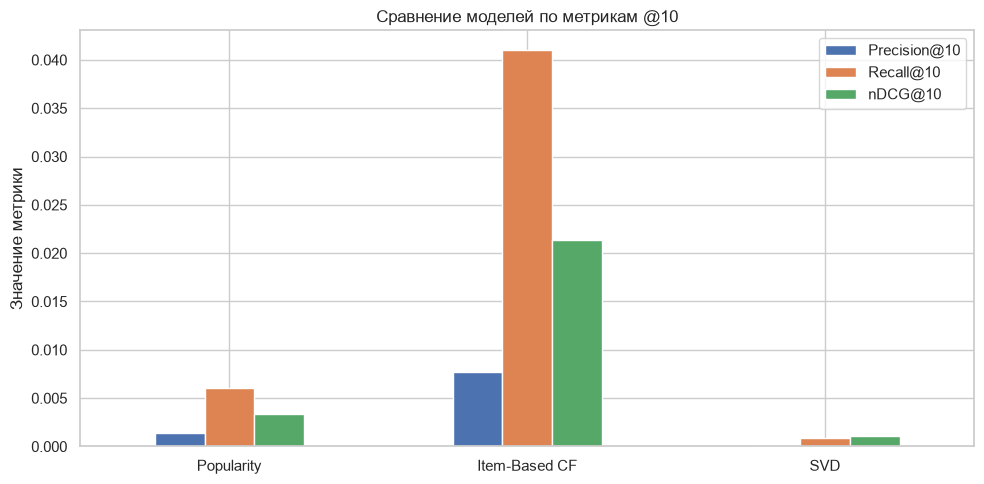

In [14]:
ax = summary[[f'Precision@{K_EVAL}', f'Recall@{K_EVAL}', f'nDCG@{K_EVAL}']].plot(kind='bar', rot=0)
ax.set_title(f'Сравнение моделей по метрикам @{K_EVAL}')
ax.set_ylabel('Значение метрики')
plt.tight_layout(); plt.show()

**Интерпретация результатов:**

- **Item-Based CF — лучшая по топ-N метрикам.** Локальные соседства «похожих книг» хорошо работают даже на разреженных данных: для рекомендации достаточно нескольких оценок пользователя на популярные «якорные» книги.
- **SVD — лучшая по RMSE, но слабее в ранжировании.** Модель обучалась минимизировать ошибку предсказания оценки (RMSE), а не качество топ-N: это разные цели. При ~15 оценках на пользователя латентные факторы пользователей шумные, и в ранжировании доминирует смещение книги `b_i` — топ SVD почти совпадает с неперсонализированным списком книг с высоким средним рейтингом (в т.ч. у книг с небольшим числом оценок, где среднее завышено). Для топ-N-качества SVD лучше обучать ранжирующими лоссами (BPR) или применять ALS к неявному фидбэку.
- **Popularity — неперсонализированный бейзлайн.** Метрики низкие, но ненулевые благодаря смещению популярности в данных; при этом список одинаков для всех.
- Абсолютные значения метрик невысокие — это следствие экстремальной разреженности (заполненность матрицы ~0.15%, в тесте у пользователя в среднем ~2–3 релевантные книги из 10 000).

## Этап 6. Гибридизация и выводы

### Гибридный подход против холодного старта

Предлагаемая стратегия — **переключающийся (switching) гибрид** с взвешиванием по объёму данных:

1. **Новый пользователь без оценок** → неперсонализированный топ популярных (плюс демографические/жанровые предпочтения из онбординга, если есть).
2. **Новая книга без оценок** → контентная модель (TF-IDF по названию и тегам): книга попадает в рекомендации как «похожая на…» ещё до появления оценок.
3. **Пользователь с малым числом оценок** → смесь контентной модели (по профилю из понравившихся книг) и популярности.
4. **Активный пользователь и «прогретая» книга** → SVD (или ансамбль SVD + Item-Based CF с весами, подобранными по валидации).

Практически: итоговый скор = `w_svd · ŷ_svd + w_cf · ŷ_cf + w_pop · zscore(popularity)`, где веса зависят от числа оценок пользователя и книги; при отсутствии оценок у книги `w_svd = w_cf = 0` и работает контентная ветвь.

### Выводы по работе

**Какая модель лучшая и почему.** По топ-N метрикам (Precision@K / Recall@K / nDCG@K) на наших данных лучшее качество показала **Item-Based CF**: локальные соседства похожих книг устойчивы к разреженности и дают персонализацию уже по нескольким оценкам. **SVD** оказалась лучшей по RMSE, но слабее в ранжировании, поскольку обучалась под pointwise-ошибку, а не под качество топ-N, — при малом числе оценок на пользователя её топ вырождается в сортировку по смещениям популярности.

**Сильные и слабые стороны моделей:**

| Модель | Сильные стороны | Слабые стороны |
|---|---|---|
| Popularity | Простая, стабильная, работает при холодном старте пользователя | Нет персонализации; усиливает смещение популярности; не рекомендует «длинный хвост» |
| Content (TF-IDF) | Решает холодный старт книги; объяснимые рекомендации | Нужны метаданные; поверхностные признаки (теги ≠ вкус); нет персонализации по оценкам |
| Item-Based CF | Персонализация без обучения; интерпретируемость («похожие книги») | O(n²) по памяти/времени; плохо работает при разреженности; холодный старт книги |
| SVD | Лучшие метрики; масштабируется (SGD); компактное представление | Требует обучения и тюнинга; холодный старт пользователя/книги; неинтерпретируемые факторы |

**Идеи дальнейшего улучшения:**
- обучать SVD под задачу ранжирования: pairwise-лосс (BPR) или ALS на неявном фидбэке (оценка ≥ 4 → 1) вместо pointwise RMSE;
- более сложные текстовые эмбеддинги описаний (Word2Vec, BERT) вместо TF-IDF;
- добавление фич пользователей (возраст, география, активность) и книг (автор, год, жанры) → факторизационные машины / SVD++;
- нейросетевые подходы (NCF, двухбашенные модели, sequential-модели типа SASRec);
- учёт времени оценки (дрейф вкусов), кросс-валидация по времени;
- калибровка разнообразия и новизны (reranking, MMR), борьба со смещением популярности (IPS/дебайасинг);
- онлайн-обновление модели и A/B-тестирование как финальный критерий качества.